# World Happiness 2017: Clustering Countries with Gaussian Mixture Models

## 1. Install and import the libraries

In [1]:
!pip install -q plotly==5.20.0
!pip install -q "jupyterlab>=3" "ipywidgets>=7.6"

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from scipy import stats
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import MinMaxScaler, Normalizer, StandardScaler

## 2. Download the data

In [4]:
!wget -O WorldHappinessReport.zip https://github.com/goitacademy/NUMERICAL-PROGRAMMING-IN-PYTHON/blob/main/WorldHappinessReport.zip?raw=true

Saving to: 'WorldHappinessReport.zip'


'WorldHappinessReport.zip' saved


## 3. Unzip the data

In [5]:
!unzip -o WorldHappinessReport.zip

Archive:  WorldHappinessReport.zip
  inflating: 2015.csv                
  inflating: 2016.csv                
  inflating: 2017.csv                
  inflating: 2018.csv                
  inflating: 2019.csv                


## 4. Read the data, statistics and feature types

In [6]:
data_dataframe = pd.read_csv('2017.csv')
data_dataframe.head()

,Country,Happiness.Rank,Happiness.Score,Whisker.high,Whisker.low,Economy..GDP.per.Capita.,Family,Health..Life.Expectancy.,Freedom,Generosity,Trust..Government.Corruption.,Dystopia.Residual
0,Norway,1,7.537,7.594445,7.479556,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2.277027
1,Denmark,2,7.522,7.581728,7.462272,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2.313707
2,Iceland,3,7.504,7.622030,7.385970,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527,2.322715
3,Switzerland,4,7.494,7.561772,7.426227,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007,2.276716
4,Finland,5,7.469,7.527542,7.410458,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612,2.430182


In [7]:
data_dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        155 non-null    str    
 1   Happiness.Rank                 155 non-null    int64  
 2   Happiness.Score                155 non-null    float64
 3   Whisker.high                   155 non-null    float64
 4   Whisker.low                    155 non-null    float64
 5   Economy..GDP.per.Capita.       155 non-null    float64
 6   Family                         155 non-null    float64
 7   Health..Life.Expectancy.       155 non-null    float64
 8   Freedom                        155 non-null    float64
 9   Generosity                     155 non-null    float64
 10  Trust..Government.Corruption.  155 non-null    float64
 11  Dystopia.Residual              155 non-null    float64
dtypes: float64(10), int64(1), str(1)
memory usage: 14.7 KB


In [8]:
data_dataframe.describe().T

,count,mean,std,min,25%,50%,75%,max
Happiness.Rank,155.0,78.000000,44.888751,1.000000,39.500000,78.000000,116.500000,155.000000
Happiness.Score,155.0,5.354019,1.131230,2.693000,4.505500,5.279000,6.101500,7.537000
Whisker.high,155.0,5.452326,1.118542,2.864884,4.608172,5.370032,6.194600,7.622030
Whisker.low,155.0,5.255713,1.145030,2.521116,4.374955,5.193152,6.006527,7.479556
Economy..GDP.per.Capita.,155.0,0.984718,0.420793,0.000000,0.663371,1.064578,1.318027,1.870766
Family,155.0,1.188898,0.287263,0.000000,1.042635,1.253918,1.414316,1.610574
Health..Life.Expectancy.,155.0,0.551341,0.237073,0.000000,0.369866,0.606042,0.723008,0.949492
Freedom,155.0,0.408786,0.149997,0.000000,0.303677,0.437454,0.516561,0.658249
Generosity,155.0,0.246883,0.134780,0.000000,0.154106,0.231538,0.323762,0.838075
Trust..Government.Corruption.,155.0,0.123120,0.101661,0.000000,0.057271,0.089848,0.153296,0.464308


In [9]:
print('Missing values:', data_dataframe.isna().sum().sum())
print('Duplicated countries:', data_dataframe['Country'].duplicated().sum())

Missing values: 0
Duplicated countries: 0


## 5. Distributions of the numeric features

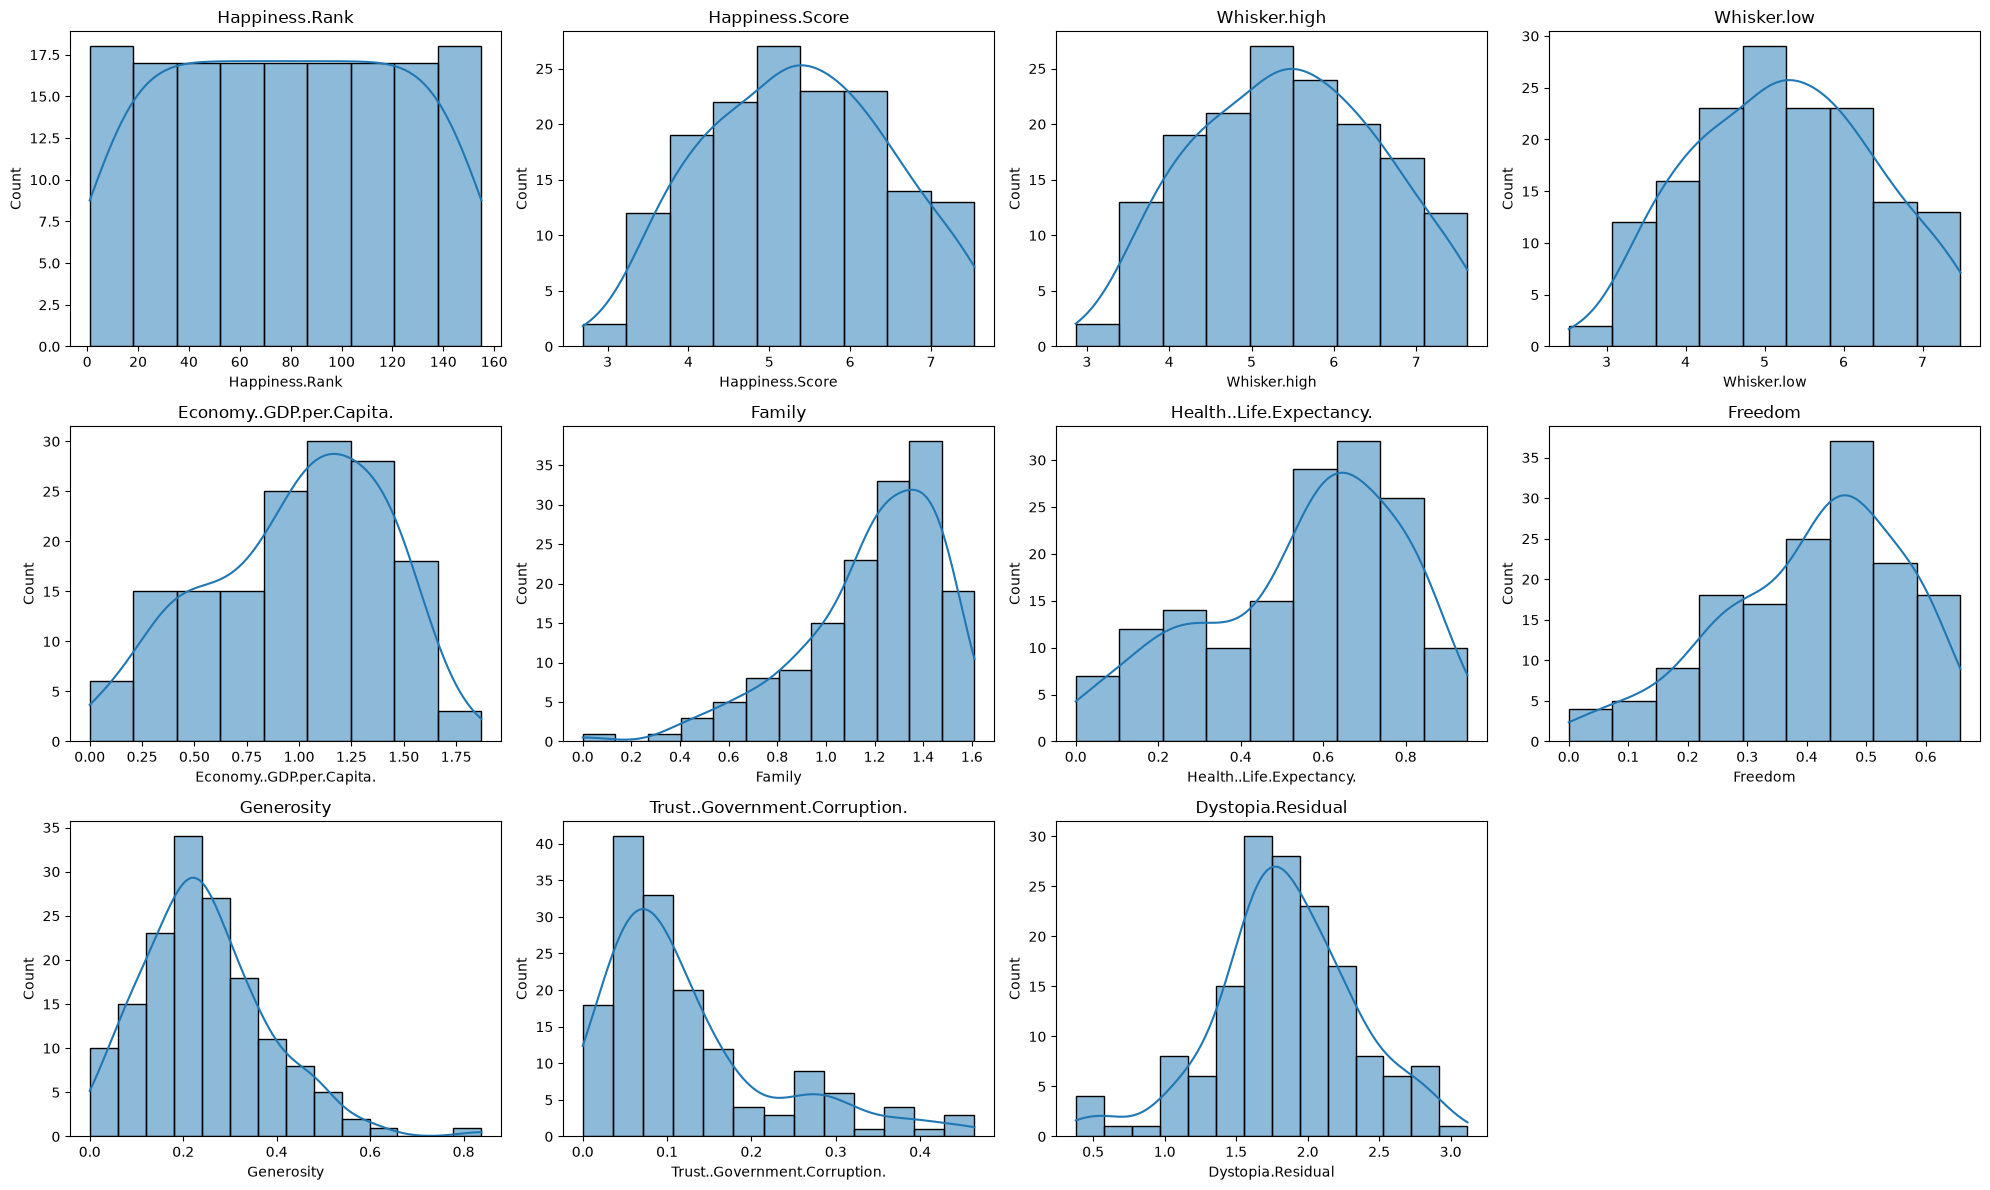

In [15]:
numeric_columns = data_dataframe.select_dtypes('number').columns.tolist()

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, column in zip(axes.ravel(), numeric_columns):
  sns.histplot(data=data_dataframe, x=column, kde=True, ax=ax)
  ax.set_title(column)
for ax in axes.ravel()[len(numeric_columns):]:
  ax.axis('off')

plt.tight_layout()
plt.show()

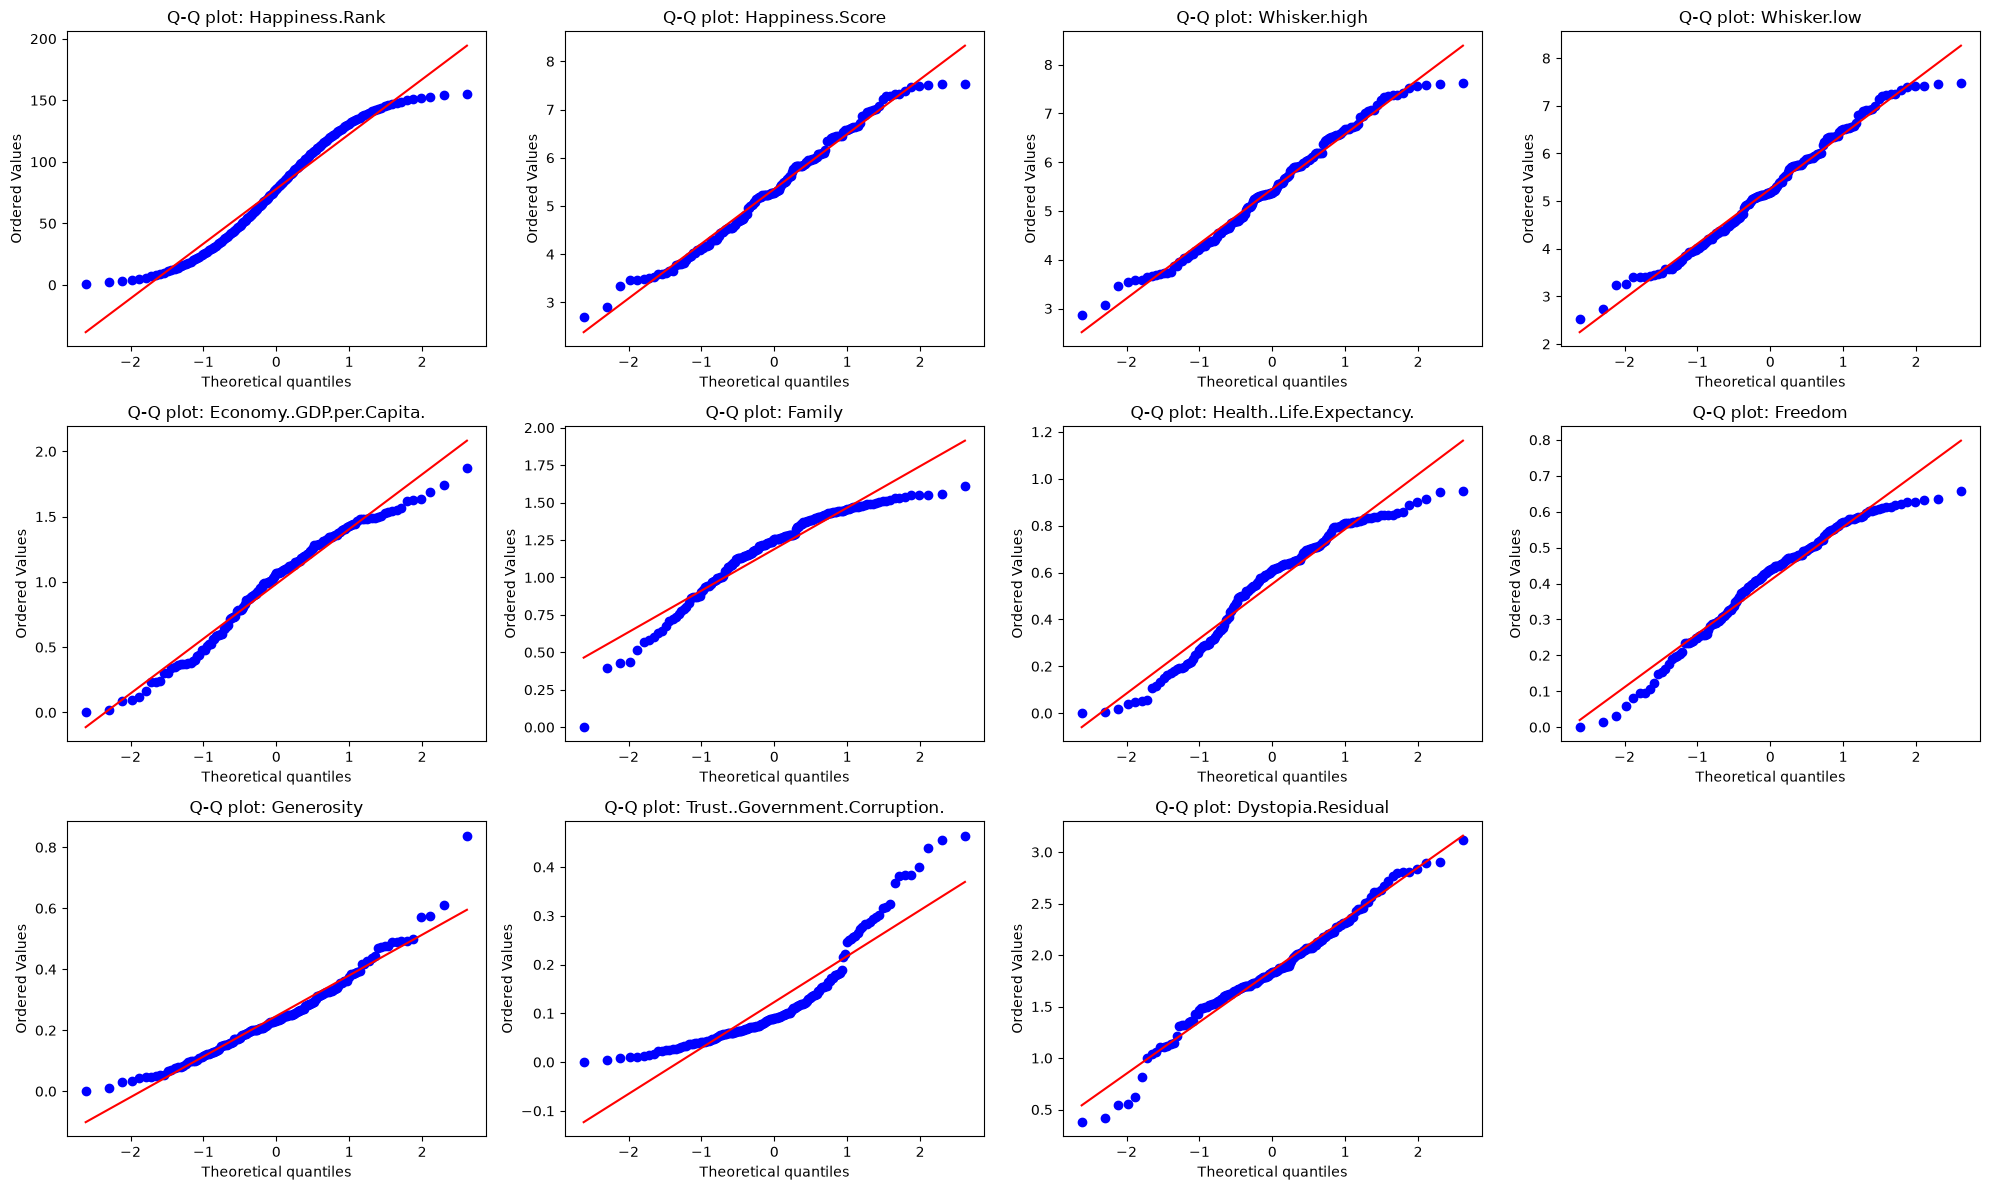

In [18]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, column in zip(axes.ravel(), numeric_columns):
  stats.probplot(data_dataframe[column].to_numpy(), dist='norm', plot=ax)
  ax.set_title(f'Q-Q plot: {column}')
for ax in axes.ravel()[len(numeric_columns):]:
  ax.axis('off')

plt.tight_layout()
plt.show()

In [20]:
normality_rows = []
for column in numeric_columns:
  values = data_dataframe[column].to_numpy()
  normality_rows.append({
    'feature': column,
    'skewness': stats.skew(values),
    'kurtosis': stats.kurtosis(values),
    'Shapiro-Wilk p-value': stats.shapiro(values).pvalue,
  })

normality = pd.DataFrame(normality_rows).set_index('feature')
normality['normal (p > 0.05)'] = normality['Shapiro-Wilk p-value'] > 0.05
normality.round(4)

,skewness,kurtosis,Shapiro-Wilk p-value,normal (p > 0.05)
feature,,,,
Happiness.Rank,0.0000,-1.2001,0.0001,False
Happiness.Score,0.0095,-0.7649,0.0522,True
Whisker.high,0.0083,-0.7900,0.0508,True
Whisker.low,0.0090,-0.7387,0.0628,True
Economy..GDP.per.Capita.,-0.3869,-0.6936,0.0017,False
Family,-1.1696,1.4477,0.0000,False
Health..Life.Expectancy.,-0.5724,-0.6053,0.0000,False
Freedom,-0.6098,-0.2402,0.0002,False
Generosity,0.8900,1.6492,0.0001,False


## 6. Feature selection and correlation matrix

In [23]:
FEATURES = {
  'Economy..GDP.per.Capita.': 'Economy',
  'Family': 'Family',
  'Health..Life.Expectancy.': 'Health',
  'Freedom': 'Freedom',
  'Generosity': 'Generosity',
  'Trust..Government.Corruption.': 'Trust',
}

happiness = data_dataframe.rename(columns=FEATURES)
feature_names = list(FEATURES.values())
original_dataframe = happiness.loc[:, feature_names]
original_dataframe.head()

,Economy,Family,Health,Freedom,Generosity,Trust
0,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964
1,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770
2,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527
3,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007
4,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612


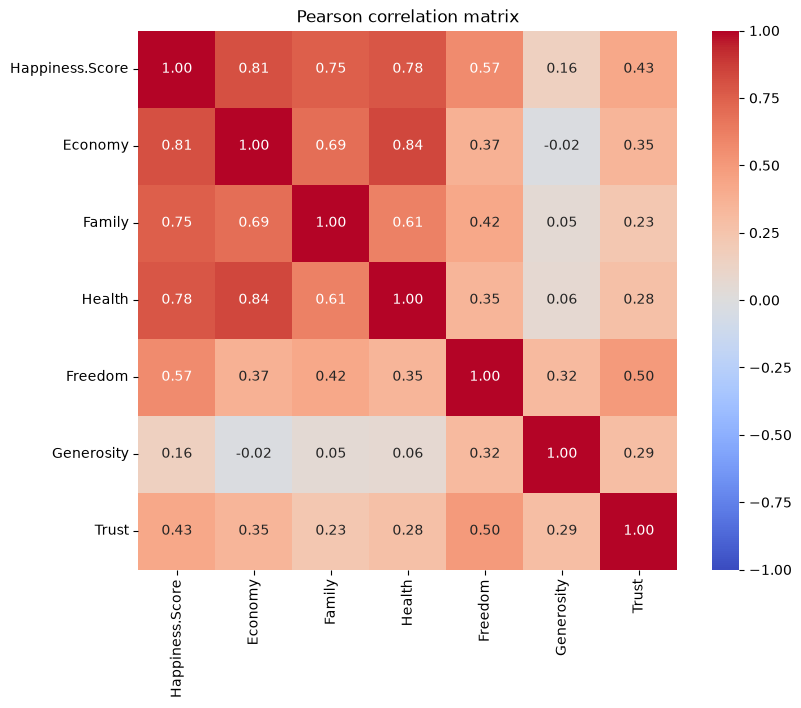

In [27]:
corr = happiness.loc[:, ['Happiness.Score', *feature_names]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Pearson correlation matrix')
plt.show()

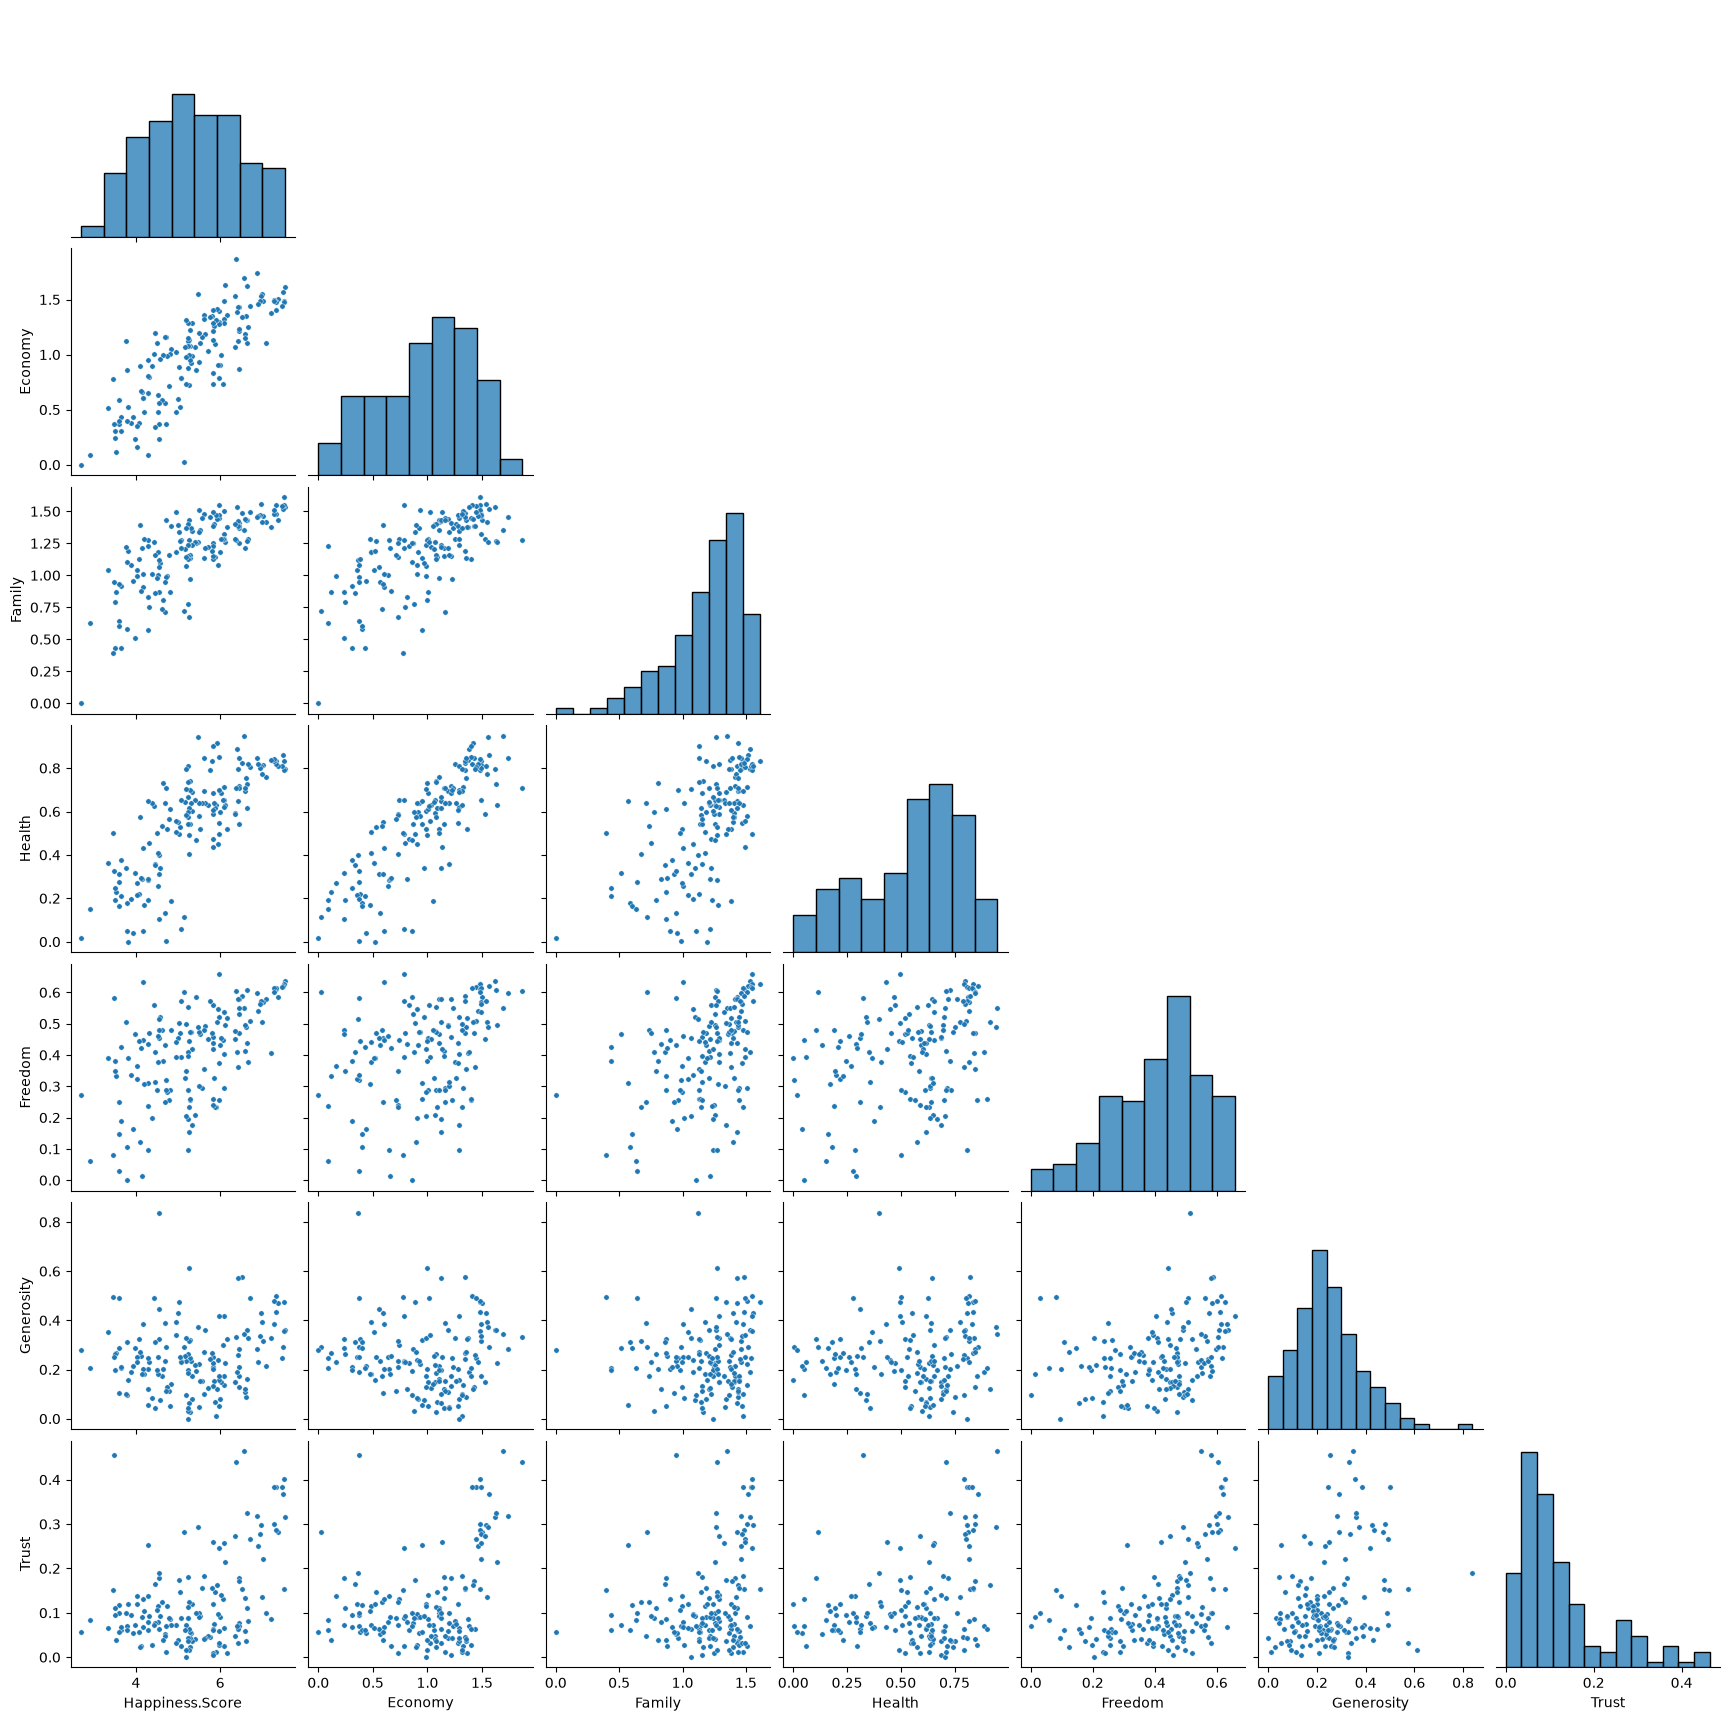

In [29]:
sns.pairplot(happiness.loc[:, ['Happiness.Score', *feature_names]], corner=True, plot_kws={'s': 15})
plt.show()

In [32]:
upper_i, upper_j = np.triu_indices(len(corr), k=1)
pairs = pd.DataFrame({
  'feature 1': corr.index[upper_i],
  'feature 2': corr.columns[upper_j],
  'r': corr.to_numpy()[upper_i, upper_j],
})
pairs['|r|'] = pairs['r'].abs()
pairs['strength'] = pd.cut(pairs['|r|'], bins=[0, 0.3, 0.5, 0.7, 1], labels=['weak', 'moderate', 'strong', 'very strong'])
pairs.sort_values('|r|', ascending=False).round(3).reset_index(drop=True)

,feature 1,feature 2,r,|r|,strength
0,Economy,Health,0.843,0.843,very strong
1,Happiness.Score,Economy,0.812,0.812,very strong
2,Happiness.Score,Health,0.782,0.782,very strong
3,Happiness.Score,Family,0.753,0.753,very strong
4,Economy,Family,0.688,0.688,strong
5,Family,Health,0.612,0.612,strong
6,Happiness.Score,Freedom,0.570,0.570,strong
7,Freedom,Trust,0.499,0.499,moderate
8,Happiness.Score,Trust,0.429,0.429,moderate
9,Family,Freedom,0.425,0.425,moderate


## 7. Happiness score by country

In [34]:
fig = px.choropleth(data_dataframe,
                    locations='Country',
                    color='Happiness.Score',
                    locationmode='country names',
                    )
fig.update_layout(title='Happiness Index 2017')
fig.show()

## 8. Data scaling

In [37]:
def data_scale(data: pd.DataFrame, scaler_type: str = 'minmax') -> np.ndarray:
  scalers = {
    'minmax': MinMaxScaler(),
    'std': StandardScaler(),
    'norm': Normalizer(),
  }
  scaler = scalers[scaler_type]
  scaler.fit(data)

  return scaler.transform(data)


data_scaled = data_scale(original_dataframe)
df_scaled = pd.DataFrame(data_scaled, columns=original_dataframe.columns)
print(df_scaled.head())

    Economy    Family    Health   Freedom  Generosity     Trust
0  0.864065  0.952160  0.839045  0.965323    0.431957  0.680505
1  0.792394  0.963086  0.834726  0.951019    0.423924  0.863156
2  0.791458  1.000000  0.877892  0.952775    0.567420  0.330657
3  0.836545  0.941845  0.903779  0.942001    0.346686  0.790440
4  0.771648  0.956334  0.852200  0.938780    0.292913  0.824047


## 9. Statistics of the original and scaled data

In [41]:
scaled_frames = {
  scaler_type: pd.DataFrame(data_scale(original_dataframe, scaler_type), columns=original_dataframe.columns)
  for scaler_type in ['minmax', 'std', 'norm']
}

stats_comparison = pd.concat(
  {'original': original_dataframe.describe().T, **{name: frame.describe().T for name, frame in scaled_frames.items()}},
  names=['data', 'feature'],
)
stats_comparison[['mean', 'std', 'min', '50%', 'max']].round(3)

mean    std    min    50%    max
data     feature                                      
original Economy     0.985  0.421  0.000  1.065  1.871
         Family      1.189  0.287  0.000  1.254  1.611
         Health      0.551  0.237  0.000  0.606  0.949
         Freedom     0.409  0.150  0.000  0.437  0.658
         Generosity  0.247  0.135  0.000  0.232  0.838
         Trust       0.123  0.102  0.000  0.090  0.464
minmax   Economy     0.526  0.225  0.000  0.569  1.000
         Family      0.738  0.178  0.000  0.779  1.000
         Health      0.581  0.250  0.000  0.638  1.000
         Freedom     0.621  0.228  0.000  0.665  1.000
         Generosity  0.295  0.161  0.000  0.276  1.000
         Trust       0.265  0.219  0.000  0.194  1.000
std      Economy    -0.000  1.003 -2.348  0.190  2.112
         Family      0.000  1.003 -4.152  0.227  1.473
         Health     -0.000  1.003 -2.333  0.231  1.685
         Freedom     0.000  1.003 -2.734  0.192  1.669
         Generosity  0.000  1.003 -1.838 -0.114  4.401
         Trust      -0.000  1.003 -1.215 -0.328  3.367
norm     Economy     0.535  0.149  0.000  0.584  0.746
         Family      0.684  0.112  0.000  0.681  0.949
         Health      0.303  0.096  0.000  0.330  0.482
         Freedom     0.241  0.102  0.000  0.243  0.686
         Generosity  0.154  0.104  0.000  0.135  0.712
         Trust       0.071  0.052  0.000  0.058  0.344

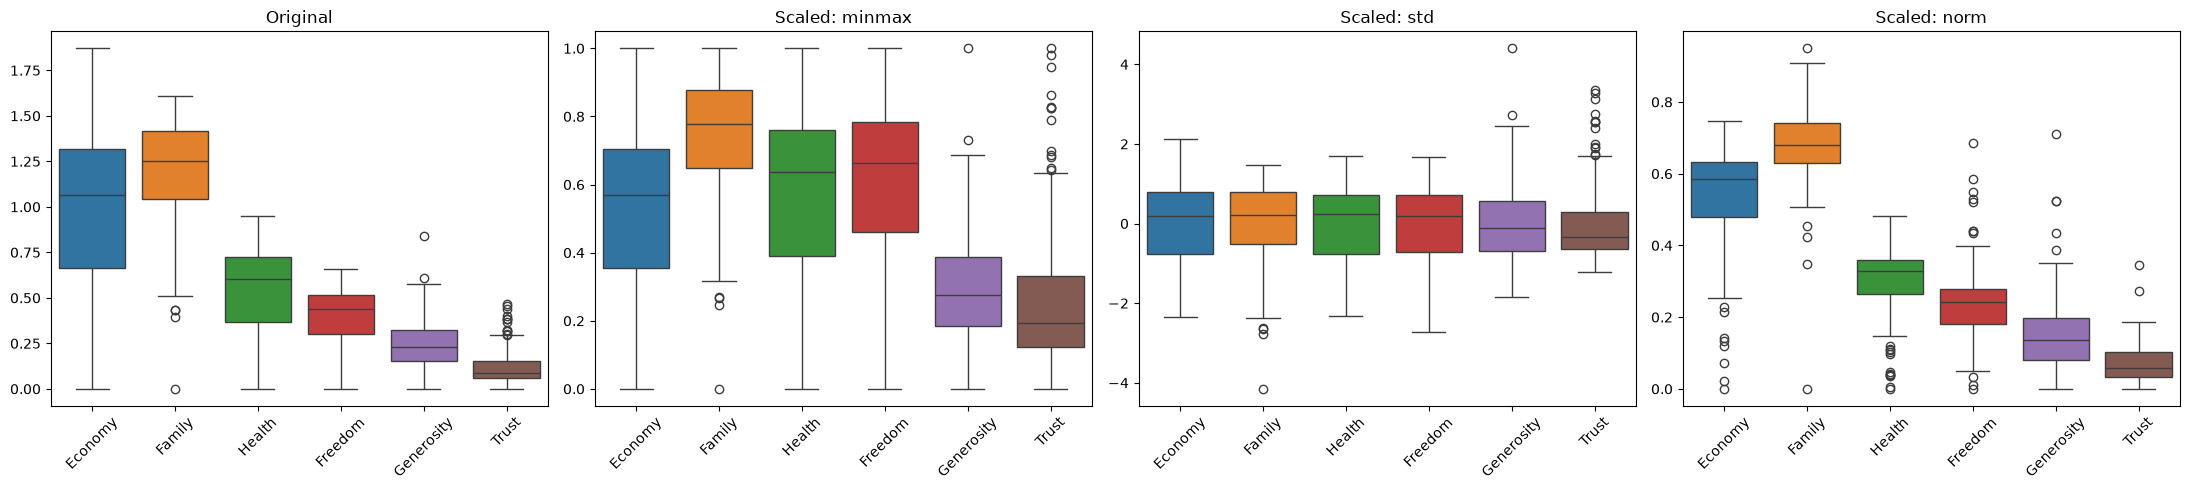

In [44]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
sns.boxplot(data=original_dataframe, ax=axes[0])
axes[0].set_title('Original')
for ax, (name, frame) in zip(axes[1:], scaled_frames.items()):
  sns.boxplot(data=frame, ax=ax)
  ax.set_title(f'Scaled: {name}')
for ax in axes:
  ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 10. Gaussian mixture clustering

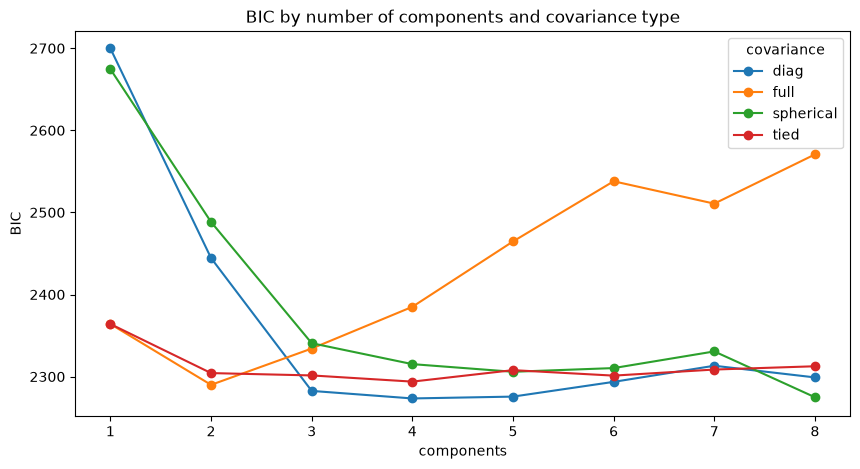

covariance,diag,full,spherical,tied
components,,,,
1,2699.7,2364.0,2674.5,2364.0
2,2444.4,2289.9,2488.4,2304.3
3,2282.6,2334.2,2340.7,2301.4
4,2273.4,2385.0,2315.2,2293.9
5,2275.6,2464.6,2305.9,2307.8
6,2293.6,2537.9,2310.4,2301.2
7,2313.2,2510.7,2330.7,2308.6
8,2299.0,2570.7,2274.8,2312.6


In [58]:
X_std = scaled_frames['std'].to_numpy()

component_rows = []
for covariance_type in ['full', 'tied', 'diag', 'spherical']:
  for n in range(1, 9):
    model = GaussianMixture(n_components=n, covariance_type=covariance_type, n_init=10, random_state=42).fit(X_std)
    component_rows.append({'covariance': covariance_type, 'components': n, 'BIC': model.bic(X_std)})

components = pd.DataFrame(component_rows)
bic_table = components.pivot(index='components', columns='covariance', values='BIC')

bic_table.plot(marker='o', figsize=(10, 5), title='BIC by number of components and covariance type')
plt.ylabel('BIC')
plt.show()

bic_table.round(1)

In [59]:
best_model = components.loc[components['BIC'].idxmin()]
N_COMPONENTS = int(best_model['components'])
COVARIANCE_TYPE = str(best_model['covariance'])

print(f'Lowest BIC: {COVARIANCE_TYPE} covariance, {N_COMPONENTS} components')

Lowest BIC: diag covariance, 4 components


In [67]:
def order_by_score(labels: np.ndarray, scores: np.ndarray) -> np.ndarray:
  cluster_ids = np.unique(labels)
  mean_scores = [scores[labels == c].mean() for c in cluster_ids]
  ranking = {int(c): rank for rank, c in enumerate(cluster_ids[np.argsort(mean_scores)])}

  return np.array([ranking[int(label)] for label in labels])


gmm = GaussianMixture(n_components=N_COMPONENTS, covariance_type=COVARIANCE_TYPE, n_init=10, random_state=42)
scores = happiness['Happiness.Score'].to_numpy()
clusters = order_by_score(gmm.fit_predict(X_std), scores)

clustered = happiness.assign(Cluster=clusters)
cluster_profile = pd.DataFrame(clustered.groupby('Cluster')[['Happiness.Score', *feature_names]].mean())
cluster_profile['countries'] = clustered['Cluster'].value_counts().sort_index()
cluster_profile.round(3)

,Happiness.Score,Economy,Family,Health,Freedom,Generosity,Trust,countries
Cluster,,,,,,,,
0,4.051,0.461,0.870,0.248,0.328,0.251,0.106,43
1,5.527,1.128,1.241,0.668,0.328,0.165,0.060,51
2,5.634,1.064,1.317,0.582,0.505,0.272,0.121,39
3,7.004,1.534,1.462,0.820,0.584,0.385,0.305,22


In [69]:
for cluster_id in range(N_COMPONENTS):
  countries = clustered.loc[clustered['Cluster'] == cluster_id, 'Country'].tolist()
  print(f'Cluster {cluster_id} ({len(countries)}): {", ".join(countries[:12])}{" ..." if len(countries) > 12 else ""}')

Cluster 0 (43): Pakistan, Somalia, Nigeria, Sierra Leone, Cameroon, Bangladesh, Kenya, Mozambique, Senegal, Zambia, Ethiopia, India ...
Cluster 1 (51): Israel, Chile, Brazil, Czech Republic, Argentina, Mexico, Taiwan Province of China, Spain, Colombia, Slovakia, El Salvador, Poland ...
Cluster 2 (39): Costa Rica, Uruguay, Guatemala, Panama, France, Thailand, Saudi Arabia, Trinidad and Tobago, Kuwait, Bahrain, Malaysia, Nicaragua ...
Cluster 3 (22): Norway, Denmark, Iceland, Switzerland, Finland, Netherlands, Canada, New Zealand, Sweden, Australia, Austria, United States ...


## 11. Countries by cluster on the map

In [72]:
fig = px.choropleth(clustered.assign(Cluster=clustered['Cluster'].astype(str)),
                    locations='Country',
                    color='Cluster',
                    locationmode='country names',
                    category_orders={'Cluster': [str(c) for c in range(N_COMPONENTS)]},
                    hover_data=['Happiness.Score'],
                    )
fig.update_layout(title='Gaussian mixture clusters of countries, 2017 (0 = least happy)')
fig.show()

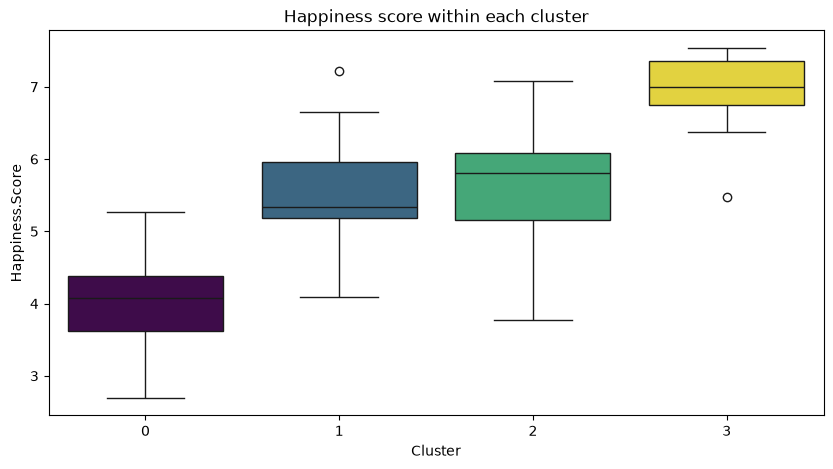

In [74]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=clustered, x='Cluster', y='Happiness.Score', hue='Cluster', palette='viridis', legend=False)
plt.title('Happiness score within each cluster')
plt.show()

## 12. Influence of the feature set on clustering

In [91]:
score_groups = np.asarray(pd.qcut(happiness['Happiness.Score'], q=N_COMPONENTS, labels=False))


def correlation_ratio(labels: np.ndarray, values: np.ndarray) -> float:
  total = ((values - values.mean()) ** 2).sum()
  between = sum((labels == c).sum() * (values[labels == c].mean() - values.mean()) ** 2 for c in np.unique(labels))

  return float(between / total)


def cluster_features(columns: list[str], scaler_type: str = 'std', n_components: int = N_COMPONENTS) -> np.ndarray:
  X = data_scale(original_dataframe.loc[:, columns], scaler_type)
  model = GaussianMixture(n_components=n_components, covariance_type=COVARIANCE_TYPE, n_init=10, random_state=42)

  return order_by_score(model.fit_predict(X), scores)


feature_sets = {
  'all six features': feature_names,
  'economy + family + health': ['Economy', 'Family', 'Health'],
  'freedom + generosity + trust': ['Freedom', 'Generosity', 'Trust'],
  'economy + health': ['Economy', 'Health'],
  'economy only': ['Economy'],
  'generosity only': ['Generosity'],
}

feature_set_rows = []
feature_set_labels = {}
for name, columns in feature_sets.items():
  labels = cluster_features(columns)
  feature_set_labels[name] = labels
  feature_set_rows.append({
    'feature set': name,
    'features': len(columns),
    'eta² (score explained)': correlation_ratio(labels, scores),
    'ARI vs. score quantiles': adjusted_rand_score(score_groups, labels),
    'cluster sizes': str(np.bincount(labels).tolist()),
  })

pd.DataFrame(feature_set_rows).set_index('feature set').round(3)

,features,eta² (score explained),ARI vs. score quantiles,cluster sizes
feature set,,,,
all six features,6,0.698,0.275,"[43, 51, 39, 22]"
economy + family + health,3,0.697,0.252,"[27, 41, 53, 34]"
freedom + generosity + trust,3,0.281,0.070,"[87, 39, 10, 19]"
economy + health,2,0.677,0.256,"[39, 28, 54, 34]"
economy only,1,0.635,0.237,"[31, 28, 46, 50]"
generosity only,1,0.061,0.016,"[1, 82, 43, 29]"


In [96]:
scaler_rows = []
for scaler_type in ['minmax', 'std', 'norm']:
  labels = cluster_features(feature_names, scaler_type)
  scaler_rows.append({
    'scaler': scaler_type,
    'eta² (score explained)': correlation_ratio(labels, scores),
    'ARI vs. score quantiles': adjusted_rand_score(score_groups, labels),
    'cluster sizes': str(np.bincount(labels).tolist()),
  })

pd.DataFrame(scaler_rows).set_index('scaler').round(3)

,eta² (score explained),ARI vs. score quantiles,cluster sizes
scaler,,,
minmax,0.709,0.287,"[43, 42, 48, 22]"
std,0.698,0.275,"[43, 51, 39, 22]"
norm,0.490,0.187,"[1, 46, 60, 48]"


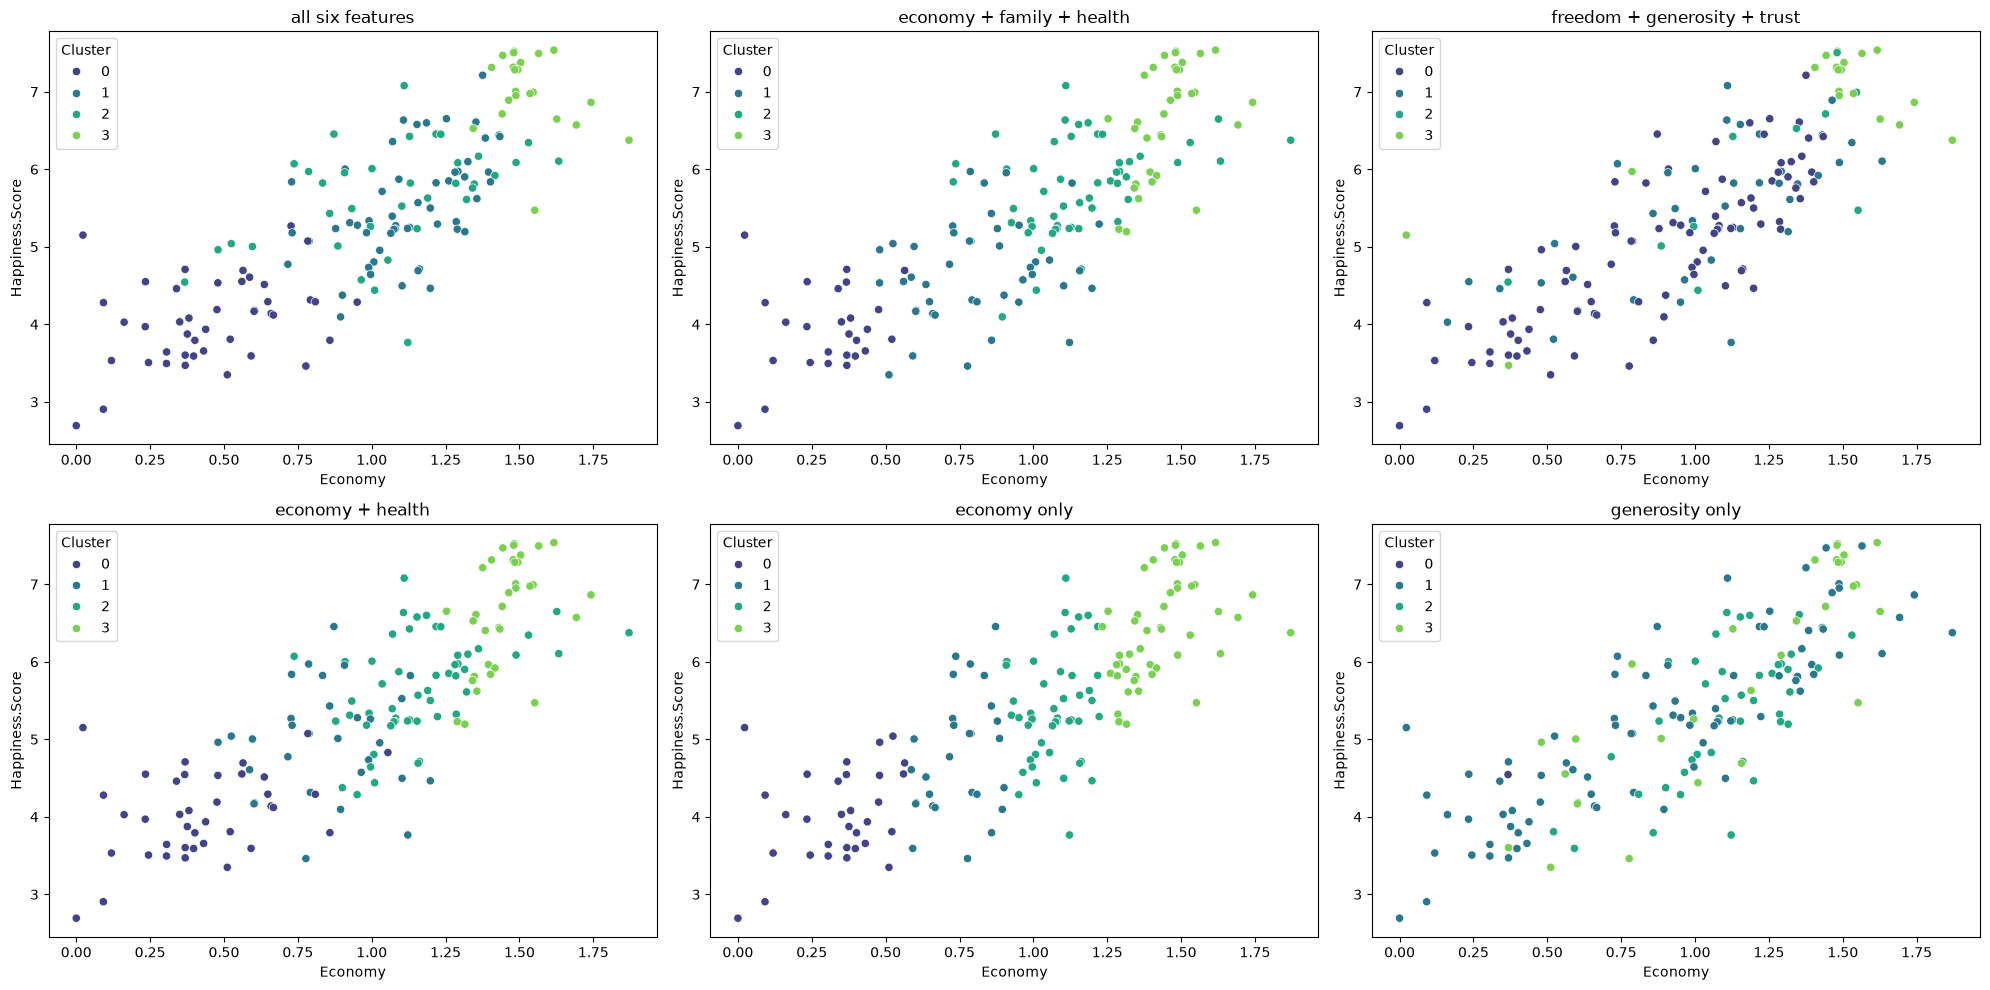

In [102]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, (name, labels) in zip(axes.ravel(), feature_set_labels.items()):
  sns.scatterplot(
    data=happiness.assign(Cluster=labels.astype(str)),
    x='Economy',
    y='Happiness.Score',
    hue='Cluster',
    hue_order=[str(c) for c in range(N_COMPONENTS)],
    palette='viridis',
    ax=ax,
  )
  ax.set_title(name)

plt.tight_layout()
plt.show()

In [104]:
fig = px.choropleth(happiness.assign(Cluster=feature_set_labels['freedom + generosity + trust'].astype(str)),
                    locations='Country',
                    color='Cluster',
                    locationmode='country names',
                    category_orders={'Cluster': [str(c) for c in range(N_COMPONENTS)]},
                    )
fig.update_layout(title='Clusters built only on freedom, generosity and trust')
fig.show()

## Conclusion

- The 2017 report has 155 countries, 11 numeric features and no missing values; rank, whiskers and dystopia residual are derived from the score, so six factor features were used for modeling.
- Only the happiness score (and its whiskers) passes the Shapiro-Wilk normality test; the factors are skewed: Family, Health and Freedom have long left tails, Generosity and Trust long right tails with outliers.
- Linear relationships: the score is very strongly correlated with Economy (0.81), Health (0.78) and Family (0.75), strongly with Freedom (0.57), moderately with Trust (0.43) and only weakly with Generosity (0.16). Economy and Health are almost collinear (0.84).
- MinMax scaling maps every feature to [0, 1], standardization gives mean 0 and std 1 but keeps outliers (Generosity up to 4.4 std), and Normalizer rescales each country row to unit length, which changes the relationships between countries rather than between features.
- BIC over 1-8 components and four covariance types picks a 4-component GMM with diagonal covariance; its clusters are ordered by happiness: 4.05 (mostly Africa and South Asia), 5.53 (Southern and Eastern Europe, South America), 5.63 (Central America, Gulf states, Southeast Asia) and 7.00 (Western Europe, North America, Australia and New Zealand).
- The cluster map repeats the happiness map well: cluster membership explains 70% of the variance of the score (eta² = 0.70), though the two middle clusters overlap in score and differ mainly in freedom and generosity.
- The feature set matters: economy, family and health alone give nearly the same result (eta² = 0.70), economy alone 0.64, while freedom + generosity + trust (0.28) or generosity alone (0.06) produce clusters that have little to do with happiness.
- MinMax and standard scaling give similar clusters (eta² 0.71 and 0.70); the row-wise Normalizer is a poor fit for this data (0.49).
- Overall, the GMM clusters follow the original distribution of countries by happiness, driven mainly by wealth, health and social support.